# Telco Customer Churn Prediction

## Project Objective

The goal of this project is to build a machine learning classification
system that predicts whether a telecom customer is likely to churn.

### Business Problem

Customer churn is an important business problem for telecom companies.
Identifying customers who are likely to leave can help the company take
retention actions.

### Machine Learning Problem

This is a binary classification problem.

- Target = Churn
- `Yes` = Customer churned
- `No` = Customer stayed

### Project Workflow

1. Dataset and business understanding
2. Data inspection and quality analysis
3. Exploratory data analysis
4. Data cleaning and feature preparation
5. Train/test split and baseline model
6. Multiple classification models
7. Cross-validation and hyperparameter tuning
8. Final model evaluation
9. Feature importance and business insights
10. Save the final model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_recall_curve
)

import joblib

In [2]:
data_path = Path("../../data/raw/telco_customer_churn.csv")

df = pd.read_csv(data_path)

print("Shape:", df.shape)

df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
df.sample(5, random_state=42)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,...,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [7]:
print(df["TotalCharges"].dtype)

str


In [8]:
print(
    "Blank TotalCharges:",
    (df["TotalCharges"].astype(str).str.strip() == "").sum()
)

Blank TotalCharges: 11


In [9]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [10]:
print(df.isnull().sum().sort_values(ascending=False).head(10))

TotalCharges      11
gender             0
SeniorCitizen      0
Partner            0
customerID         0
Dependents         0
tenure             0
MultipleLines      0
PhoneService       0
OnlineSecurity     0
dtype: int64


In [11]:
missing = df.isnull().sum()

print(
    missing[missing > 0].sort_values(
        ascending=False
    )
)

TotalCharges    11
dtype: int64


In [12]:
df["Churn"]=df["Churn"].map({
    "Yes":1,
    "No":0
})

In [13]:
print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [14]:
print("Shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicates:")
print(df.duplicated().sum())

Shape: (7043, 21)

Missing values:
11

Duplicates:
0


## Data Cleaning Summary

The raw Telco Customer Churn dataset was inspected for duplicate records,
missing values, incorrect data types, and unnecessary columns.

`TotalCharges` contained blank values, so it was converted to a numeric
datatype using `pd.to_numeric()` with invalid values converted to NaN.

The target variable `Churn` was converted from `Yes`/`No` into binary
values where 1 represents churn and 0 represents customers who stayed.

The original customer ID will not be used as a predictive feature.

Missing values will be handled inside the machine learning preprocessing
pipeline to avoid data leakage.

In [15]:
churn_counts = df["Churn"].value_counts()

print(churn_counts)
print(
    df["Churn"].value_counts(normalize=True) * 100
)

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


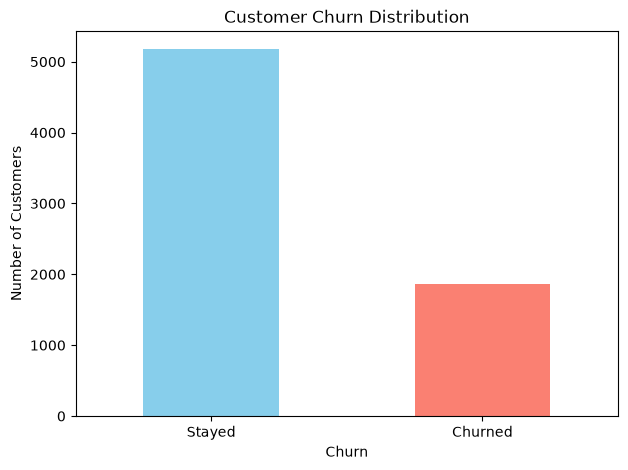

In [19]:
churn_counts.plot(kind="bar", color=["skyblue", "salmon"],figsize=(7, 5))

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["Stayed", "Churned"], rotation=0)
plt.show()

In [20]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                   0          1
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


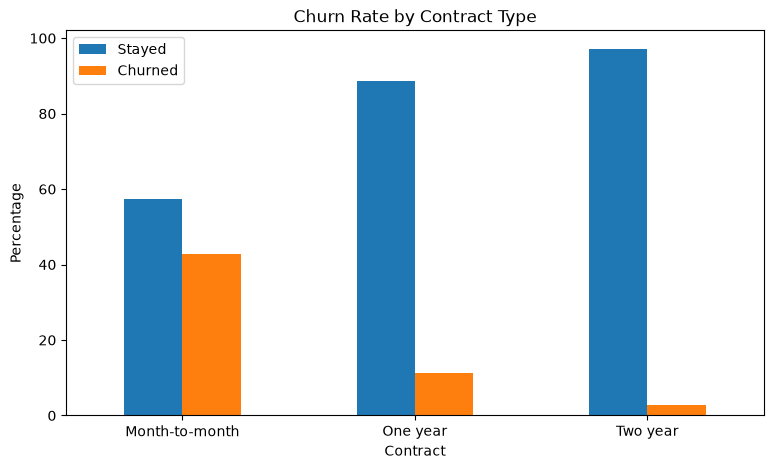

In [21]:
contract_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(["Stayed", "Churned"])
plt.show()

<Figure size 900x500 with 0 Axes>

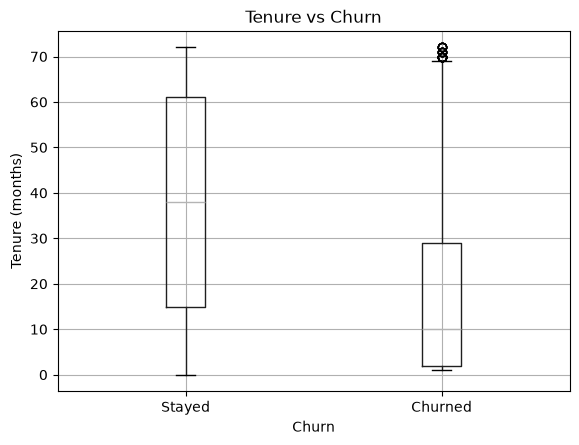

In [22]:
plt.figure(figsize=(9, 5))

df.boxplot(
    column="tenure",
    by="Churn"
)

plt.title("Tenure vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.xticks([1, 2], ["Stayed", "Churned"])

plt.show()

<Figure size 900x500 with 0 Axes>

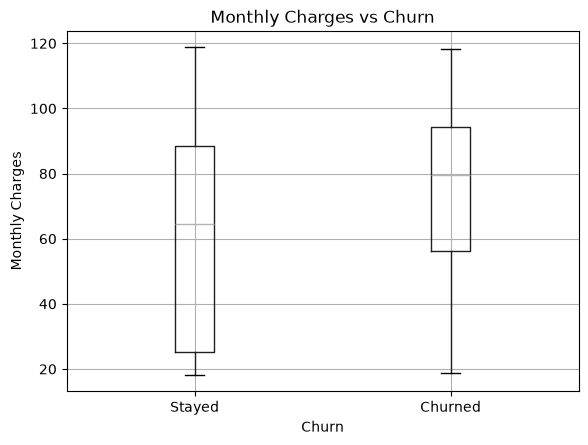

In [23]:
plt.figure(figsize=(9, 5))

df.boxplot(
    column="MonthlyCharges",
    by="Churn"
)

plt.title("Monthly Charges vs Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.xticks([1, 2], ["Stayed", "Churned"])

plt.show()

In [24]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn)

Churn                    0          1
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


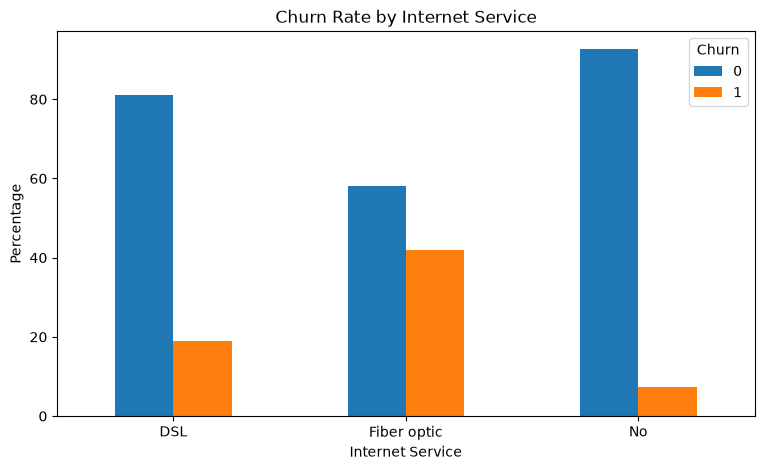

In [25]:
internet_churn.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.show()

In [26]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn)

Churn                              0          1
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


In [27]:
numeric_df = df.select_dtypes(
    include=np.number
)

numeric_df.corr()["Churn"].sort_values(
    ascending=False
)

Churn             1.000000
MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.199484
tenure           -0.352229
Name: Churn, dtype: float64

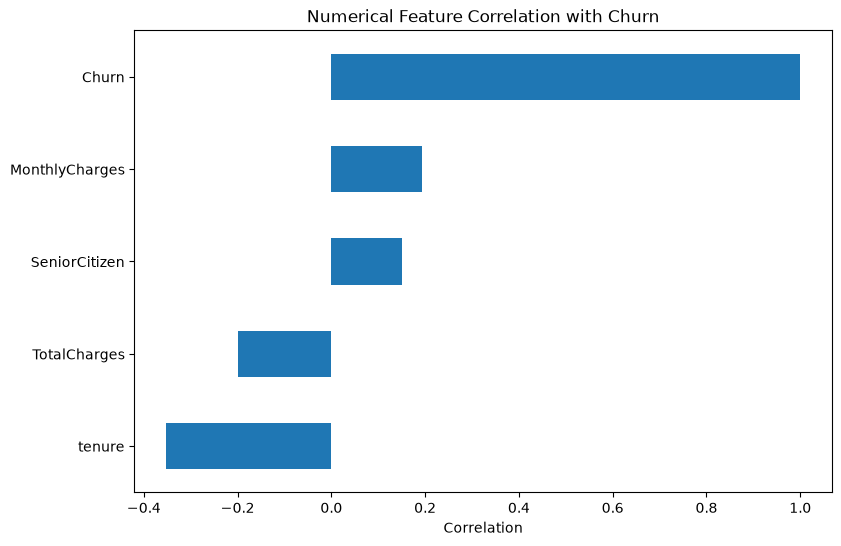

In [28]:
correlations = numeric_df.corr()["Churn"].sort_values()

correlations.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Numerical Feature Correlation with Churn")
plt.xlabel("Correlation")
plt.show()

## Exploratory Data Analysis Summary

Exploratory analysis was performed to understand patterns associated
with customer churn.

Churn was analyzed across contract type, tenure, monthly charges,
internet service, payment method, and other customer characteristics.

The analysis helps identify potentially important predictive features
and provides business context before model training.

EDA is used for understanding patterns and generating hypotheses.
It does not prove that a feature causes customer churn.

In [30]:
X = df.drop(
    columns=["Churn", "customerID"]
)

y = df["Churn"]

In [31]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


In [32]:
numeric_features = X.select_dtypes(
    include = ["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include = ["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_26952\4045797944.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [34]:
print(
    "Training distribution:"
)

print(
    y_train.value_counts(normalize=True)
)

print(
    "\nTesting distribution:"
)

print(
    y_test.value_counts(normalize=True)
)

Training distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


## Feature Preparation and Data Splitting Summary

The customer ID was removed because it is an identifier rather than a
meaningful predictive feature.

The remaining features were separated into numerical and categorical
features.

The dataset was divided into training and testing sets using an 80/20
split with stratification to preserve the churn class distribution.

The test set is kept separate so that it can provide an unbiased final
evaluation of the trained model.

In [35]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [36]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

In [37]:
preprocessor = ColumnTransformer([
    (
        "num",
        numeric_transformer,
        numeric_features
    ),
    (
        "cat",
        categorical_transformer,
        categorical_features
    )
])

In [38]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),  
])

In [39]:
logistic_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [40]:
y_pred = logistic_pipeline.predict(X_test)

y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

In [41]:
def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1":f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    return metrics

In [42]:
baseline_results = evaluate_model(logistic_pipeline, X_test, y_test)

print(pd.Series(baseline_results))

Accuracy     0.805536
Precision    0.657233
Recall       0.558824
F1           0.604046
ROC-AUC      0.841861
dtype: float64


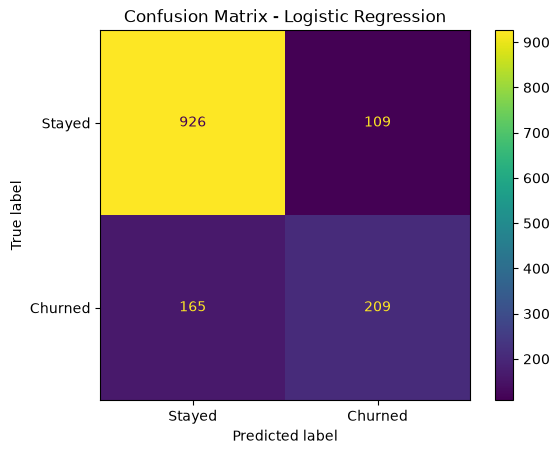

In [43]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels = ["Stayed", "Churned"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [44]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Stayed",
            "Churned"
        ]
    )
)

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [46]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000)),
    ]),

    "Decision Tree":Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "KNN": Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier(
            n_neighbors=7
        ))
    ]),

    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("model", SVC(
            probability=True,
            random_state=42
        ))
    ])
}

In [49]:
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_test, y_test)

    metrics["Model"] = name

    results.append(metrics)

results_df = pd.DataFrame(results)

results_df = results_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
]

print(
    results_df.sort_values(
        "F1",
        ascending=False
    ).round(4)
)

c:\Users\SAMSUNG\OneDrive\Desktop\PythonProjects\nupa-ml-project\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.8055     0.6572  0.5588  0.6040   0.8419
1        Decision Tree    0.7984     0.6347  0.5668  0.5989   0.8303
3                  KNN    0.7651     0.5556  0.5749  0.5650   0.8048
4                  SVM    0.7913     0.6418  0.4840  0.5518   0.7905
2        Random Forest    0.7779     0.6034  0.4759  0.5321   0.8162


## Baseline Modeling Summary

A complete preprocessing pipeline was created to handle numerical and
categorical features.

Numerical features were median-imputed and standardized. Categorical
features were imputed and one-hot encoded.

The preprocessing steps were combined with the models using Scikit-learn
Pipeline and ColumnTransformer.

Five classification algorithms were trained:

- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors
- Support Vector Machine

The models were compared using accuracy, precision, recall, F1-score,
and ROC-AUC.

The test set was kept separate from preprocessing and model training to
reduce the risk of data leakage.

In [50]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [51]:
cv_results = []

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": np.mean(scores["test_accuracy"]),
        "Precision": np.mean(scores["test_precision"]),
        "Recall": np.mean(scores["test_recall"]),
        "F1": np.mean(scores["test_f1"]),
        "ROC-AUC": np.mean(scores["test_roc_auc"])
    })

cv_results_df = pd.DataFrame(cv_results)

print(
    cv_results_df.sort_values(
        "F1",
        ascending=False
    ).round(4)
)

                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.8021     0.6529  0.5431  0.5923   0.8461
4                  SVM    0.8035     0.6772  0.4977  0.5735   0.7998
3                  KNN    0.7756     0.5819  0.5498  0.5651   0.7989
1        Decision Tree    0.7914     0.6345  0.5130  0.5649   0.8289
2        Random Forest    0.7842     0.6215  0.4789  0.5408   0.8182


In [52]:
lg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

In [53]:
param_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear", "saga"]
}

In [54]:
grid_search = GridSearchCV(
    estimator=lg_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


c:\Users\SAMSUNG\OneDrive\Desktop\PythonProjects\nupa-ml-project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\SAMSUNG\OneDrive\Desktop\PythonProjects\nupa-ml-project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__penalty': ['l1', 'l2'], 'model__solver': ['liblinear', 'saga']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_pl

In [55]:
print(
    "Best Parameters:"
)

print(
    grid_search.best_params_
)

Best Parameters:
{'model__C': 100.0, 'model__penalty': 'l1', 'model__solver': 'liblinear'}


In [56]:
print(
    "Best CV F1:",
    grid_search.best_score_
)

Best CV F1: 0.5989753521608829


In [57]:
best_model = grid_search.best_estimator_

In [58]:
final_predictions = best_model.predict(X_test)

final_probabilities = best_model.predict_proba(X_test)[:, 1]

In [59]:
final_results = {
    "Accuracy": accuracy_score(
        y_test,
        final_predictions
    ),
    
    "Precision": precision_score(
        y_test,
        final_predictions
    ),
    
    "Recall": recall_score(
        y_test,
        final_predictions
    ),
    
    "F1": f1_score(
        y_test,
        final_predictions
    ),
    
    "ROC-AUC": roc_auc_score(
        y_test,
        final_probabilities
    )
}

print(
    pd.Series(final_results).round(4)
)

Accuracy     0.8013
Precision    0.6487
Recall       0.5481
F1           0.5942
ROC-AUC      0.8408
dtype: float64


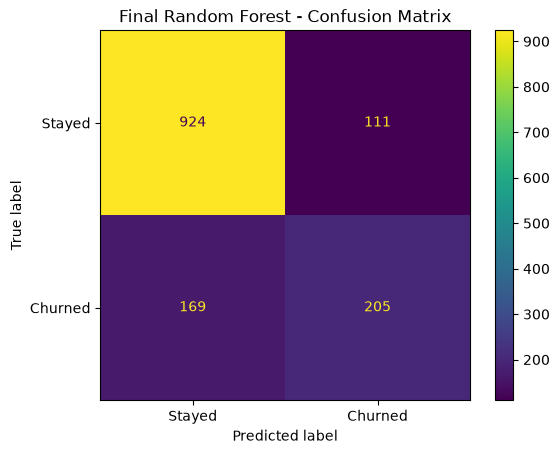

In [60]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=[
        "Stayed",
        "Churned"
    ]
)

plt.title(
    "Final Random Forest - Confusion Matrix"
)

plt.show()

In [61]:
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=[
            "Stayed",
            "Churned"
        ]
    )
)

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.65      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



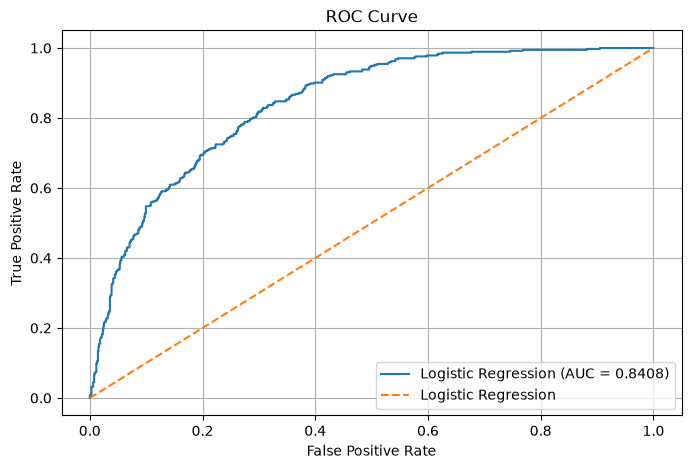

In [66]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    final_probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {final_results['ROC-AUC']:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Logistic Regression"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()
plt.grid()

plt.show()

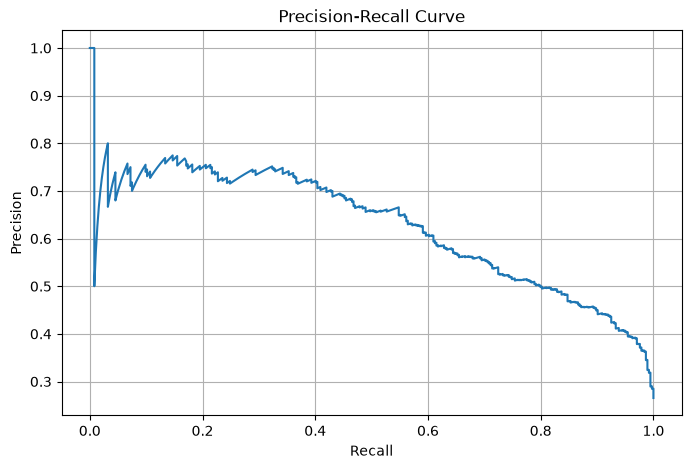

In [67]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    final_probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve"
)

plt.grid()

plt.show()

In [68]:
thresholds_to_test = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []

for threshold in thresholds_to_test:
    
    predictions = (
        final_probabilities >= threshold
    ).astype(int)
    
    threshold_results.append({
        "Threshold": threshold,
        
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

print(
    threshold_df.round(3)
)

    Threshold  Precision  Recall     F1
0        0.10      0.407   0.944  0.569
1        0.15      0.440   0.917  0.595
2        0.20      0.467   0.861  0.605
3        0.25      0.498   0.810  0.616
4        0.30      0.517   0.749  0.611
5        0.35      0.545   0.711  0.617
6        0.40      0.561   0.660  0.607
7        0.45      0.595   0.612  0.603
8        0.50      0.649   0.548  0.594
9        0.55      0.670   0.468  0.551
10       0.60      0.718   0.401  0.515
11       0.65      0.737   0.299  0.426
12       0.70      0.747   0.182  0.292
13       0.75      0.711   0.072  0.131
14       0.80      0.786   0.029  0.057
15       0.85      1.000   0.003  0.005
16       0.90      0.000   0.000  0.000


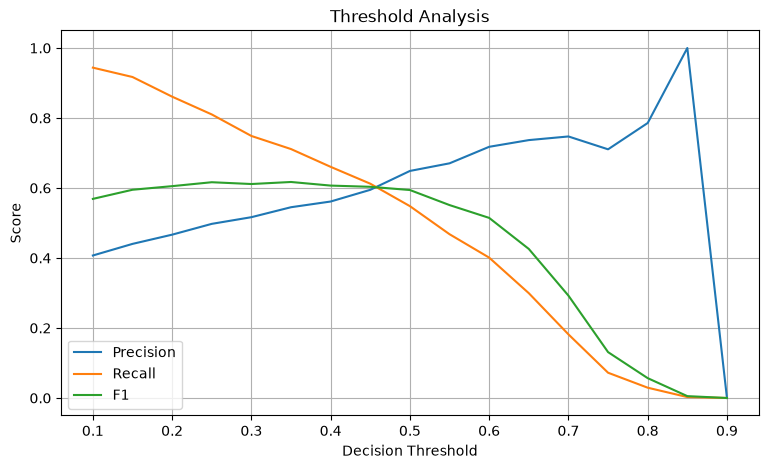

In [69]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")

plt.title(
    "Threshold Analysis"
)

plt.legend()
plt.grid()

plt.show()

In [70]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print(
    best_threshold_row
)

Threshold    0.350000
Precision    0.545082
Recall       0.711230
F1           0.617169
Name: 5, dtype: float64


## Model Evaluation and Tuning Summary

Multiple classification models were compared using cross-validation.

The evaluation considered accuracy, precision, recall, F1-score, and
ROC-AUC rather than relying only on accuracy.

Random Forest was selected for further tuning based on its validation
performance.

GridSearchCV was used to search for better Random Forest hyperparameters
using cross-validation on the training data.

After selecting the best hyperparameters, the final model was evaluated
once on the previously untouched test set.

ROC and Precision-Recall curves were also analyzed.

Decision threshold analysis was performed to understand the trade-off
between precision and recall when identifying customers likely to churn.

In [71]:
preprocessor_fitted = best_model.named_steps["preprocessor"]

feature_names = (
    preprocessor_fitted.get_feature_names_out()
)

In [73]:
lg_model = best_model.named_steps["model"]

coefficients = lg_model.coef_[0]


In [74]:
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": coefficients
})

feature_importance_df = feature_importance_df.sort_values("Importance", ascending=False)

In [75]:
feature_importance_df.head(20)

,Feature,Importance
16,cat__InternetService_Fiber optic,1.224281
32,cat__StreamingTV_Yes,0.839601
3,num__TotalCharges,0.567402
35,cat__StreamingMovies_Yes,0.469941
14,cat__MultipleLines_Yes,0.435155
43,cat__PaymentMethod_Electronic check,0.309186
26,cat__DeviceProtection_Yes,0.227586
8,cat__Dependents_No,0.219306
40,cat__PaperlessBilling_Yes,0.118126
23,cat__OnlineBackup_Yes,0.077868


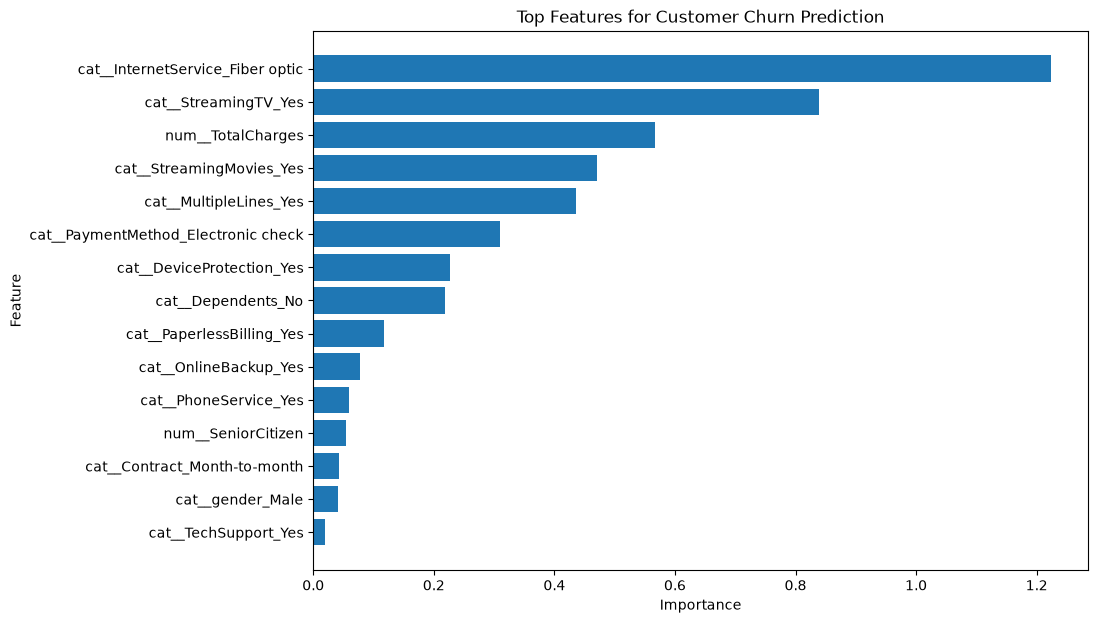

In [76]:
top_features = (
    feature_importance_df
    .head(15)
    .sort_values("Importance")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(
    "Top Features for Customer Churn Prediction"
)

plt.show()

In [77]:
model_path = Path("../../models")

model_path.mkdir(
    parents=True,
    exist_ok=True
)

In [78]:
final_model_path = model_path / "telco_customer_churn_rf_v1.joblib"

joblib.dump(
    best_model,
    final_model_path
)

print(
    "Model saved to:",
    final_model_path
)

Model saved to: ..\..\models\telco_customer_churn_rf_v1.joblib


In [79]:
loaded_model = joblib.load(final_model_path)

In [80]:
loaded_predictions = loaded_model.predict(X_test)

In [81]:
print(
    np.array_equal(
        final_predictions,
        loaded_predictions
    )
)

True


In [82]:
new_customer = pd.DataFrame({
    "gender": ["Female"],
    "SeniorCitizen": [0],
    "Partner": ["Yes"],
    "Dependents": ["No"],
    "tenure": [5],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["No"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["Yes"],
    "StreamingMovies": ["Yes"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [85.0],
    "TotalCharges": [425.0]
})

In [83]:
prediction = loaded_model.predict(
    new_customer
)

probability = loaded_model.predict_proba(
    new_customer
)[0, 1]

print(
    "Prediction:",
    "Churn" if prediction[0] == 1 else "Stay"
)

print(
    "Churn Probability:",
    probability
)

Prediction: Churn
Churn Probability: 0.829051736477868


In [85]:
final_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        final_results["Accuracy"],
        final_results["Precision"],
        final_results["Recall"],
        final_results["F1"],
        final_results["ROC-AUC"]
    ]
})

print(
    final_comparison.round(4)
)

      Metric   Score
0   Accuracy  0.8013
1  Precision  0.6487
2     Recall  0.5481
3   F1 Score  0.5942
4    ROC-AUC  0.8408


# Final Project Summary

## Project

Telco Customer Churn Prediction

## Objective

The objective of this project was to build an end-to-end machine learning
classification system capable of predicting whether a telecom customer
is likely to churn.

## Dataset

A real-world Telco Customer Churn dataset was used. It contains customer
demographic information, services, contract information, payment details,
tenure, and billing information.

## Machine Learning Problem

This is a binary classification problem.

- `0` → Customer stayed
- `1` → Customer churned

## Workflow

The project followed a complete machine learning workflow:

1. Dataset loading and business understanding
2. Data inspection
3. Data cleaning
4. Exploratory data analysis
5. Feature and target preparation
6. Train/test splitting
7. Numerical and categorical preprocessing
8. Baseline Logistic Regression
9. Comparison of multiple classification algorithms
10. Stratified cross-validation
11. Random Forest hyperparameter tuning
12. Final test-set evaluation
13. ROC and Precision-Recall analysis
14. Decision threshold analysis
15. Feature importance analysis
16. Model saving and loading
17. Prediction on new customer data

## Models Compared

- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors
- Support Vector Machine

## Evaluation Metrics

The models were evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix

Multiple metrics were used because customer churn is a classification
problem where accuracy alone may not provide enough information.

## Preprocessing

Numerical features were handled using median imputation and
StandardScaler.

Categorical features were handled using most-frequent imputation and
One-Hot Encoding.

The preprocessing steps were included inside Scikit-learn pipelines to
reduce the risk of data leakage.

## Model Selection

Cross-validation was performed on the training data to compare model
performance.

Random Forest was selected for hyperparameter tuning and the final model
was evaluated on the previously unseen test set.

## Threshold Analysis

Different probability thresholds were tested to understand the trade-off
between precision, recall, and F1-score.

This is useful because the business may prefer to identify more potential
churners even if that results in additional false positives.

## Final Model

The tuned Random Forest pipeline was saved using Joblib and successfully
loaded again for prediction.

## Business Insights

The exploratory analysis and feature importance analysis were used to
identify customer characteristics associated with churn.

The model can potentially help a telecom company identify customers at
higher risk of leaving and prioritize retention strategies.

## Key Learning

This project demonstrated how individual machine learning concepts can
be combined into a complete end-to-end classification workflow:

Data → Cleaning → EDA → Preprocessing → Training → Validation →
Hyperparameter Tuning → Evaluation → Interpretation → Model Saving →
Prediction